# Diffusive and quantum evolution of one spatial mode

The same Laplacian eigenvector can evolve under two different laws.
Diffusion multiplies it by a decaying real exponential; Schrödinger evolution
multiplies it by a unit-modulus complex phase.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Shared eigensystem and two propagators

A periodic finite-difference Laplacian supplies the spatial mode. The diffusion
coefficient and formal quantum coefficient are set equal so that the two
exponents differ only by the factor of $i$.


In [2]:
domain_length = 2.0 * np.pi
grid_size = 256
spacing = domain_length / grid_size
coordinate = spacing * np.arange(grid_size)
mode_number = 3
mode = np.cos(mode_number * coordinate)
mode /= np.max(np.abs(mode))

discrete_eigenvalue = (
    -4.0 / spacing**2
    * np.sin(np.pi * mode_number / grid_size) ** 2
)
coefficient = 0.12
sample_times = np.array([0.0, 0.4, 0.8, 1.2])
dense_time = np.linspace(0.0, sample_times[-1], 400)

diffusive_amplitude = np.exp(
    coefficient * discrete_eigenvalue * dense_time
)
quantum_amplitude = np.exp(
    1j * coefficient * discrete_eigenvalue * dense_time
)
diffusive_field = np.array([
    mode * np.exp(coefficient * discrete_eigenvalue * time_value)
    for time_value in sample_times
])
quantum_field = np.array([
    mode * np.exp(1j * coefficient * discrete_eigenvalue * time_value)
    for time_value in sample_times
])


## Verification

The quantum coefficient retains unit magnitude. The diffusive coefficient
monotonically decreases. Both fields remain proportional to the same spatial
eigenvector.


In [3]:
assert np.allclose(np.abs(quantum_amplitude), 1.0)
assert np.all(np.diff(diffusive_amplitude) < 0.0)
for field in diffusive_field:
    assert np.linalg.norm(field - field[0] / mode[0] * mode) < 1.0e-12
print(f"discrete Laplacian eigenvalue = {discrete_eigenvalue:.8f}")
print(f"final diffusive amplitude = {diffusive_amplitude[-1]:.6f}")
print(f"final quantum magnitude = {abs(quantum_amplitude[-1]):.6f}")


discrete Laplacian eigenvalue = -8.99593458
final diffusive amplitude = 0.273784
final quantum magnitude = 1.000000


## Instructive plot

The spatial panels display the same mode. The lower panels separate amplitude
decay from phase rotation, making the operator analogy precise without
identifying a probability density with a wavefunction.


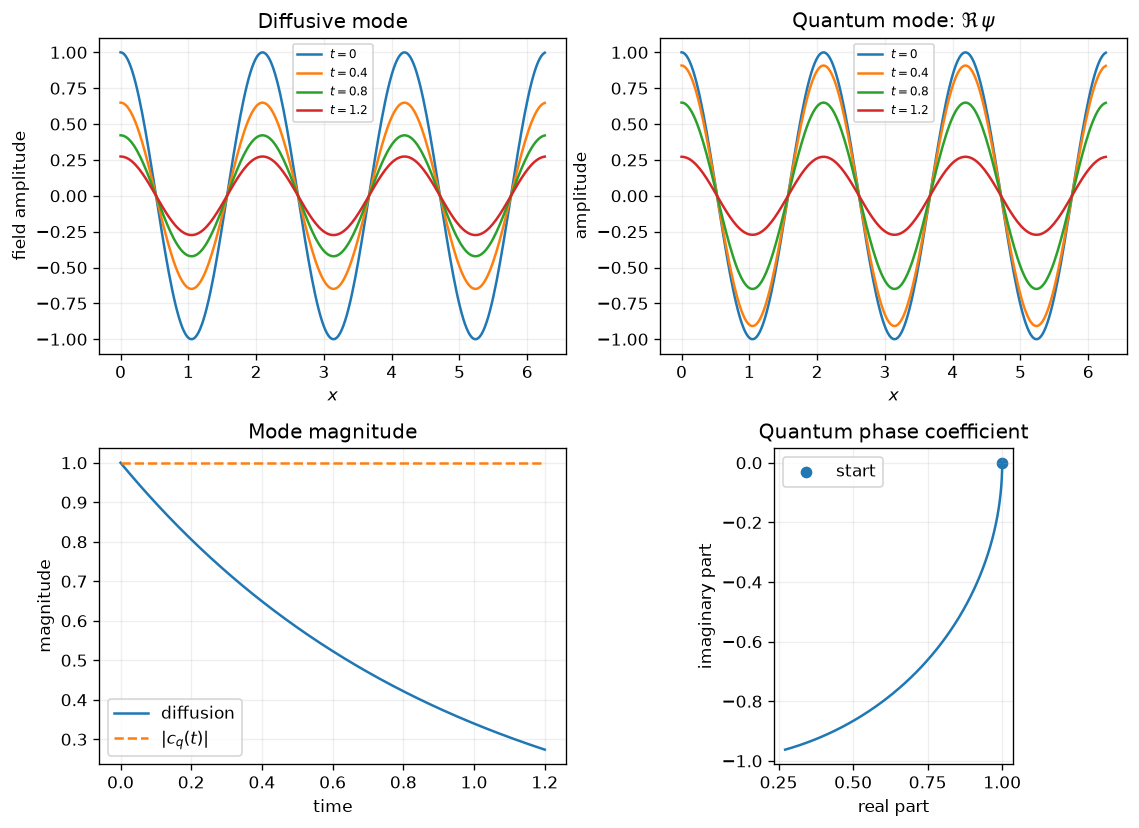

wrote lecture-notes/figures/08_brownian-motion-diffusion/10-diffusive-and-quantum-evolution.pdf


In [4]:
figure, axes = plt.subplots(2, 2, figsize=(9.5, 7.0))

for index, time_value in enumerate(sample_times):
    axes[0, 0].plot(coordinate, diffusive_field[index], label=rf"$t={time_value:g}$")
axes[0, 0].set(title="Diffusive mode", xlabel=r"$x$", ylabel="field amplitude")
axes[0, 0].legend(fontsize=7)

for index, time_value in enumerate(sample_times):
    axes[0, 1].plot(coordinate, quantum_field[index].real, label=rf"$t={time_value:g}$")
axes[0, 1].set(title=r"Quantum mode: $\Re\,\psi$", xlabel=r"$x$", ylabel="amplitude")
axes[0, 1].legend(fontsize=7)

axes[1, 0].plot(dense_time, diffusive_amplitude, label="diffusion")
axes[1, 0].plot(dense_time, np.abs(quantum_amplitude), "--", label=r"$|c_q(t)|$")
axes[1, 0].set(title="Mode magnitude", xlabel="time", ylabel="magnitude")
axes[1, 0].legend()

axes[1, 1].plot(quantum_amplitude.real, quantum_amplitude.imag)
axes[1, 1].scatter([quantum_amplitude[0].real], [quantum_amplitude[0].imag], label="start")
axes[1, 1].set(title="Quantum phase coefficient", xlabel="real part", ylabel="imaginary part")
axes[1, 1].set_aspect("equal", adjustable="box")
axes[1, 1].legend()

for axis in axes.flat:
    axis.grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "10-diffusive-and-quantum-evolution.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
